<a href="https://colab.research.google.com/github/enslern/The-AI-engineer-course-2026-Complete-AI-bootcamp/blob/main/text_classification_with_XLNET.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
!pip install cleantext
from cleantext import clean
import re
from transformers import XLNetTokenizer, XLNetForSequenceClassification, TrainingArguments, Trainer, pipeline
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import datasets
!pip install evaluate
import evaluate
import random

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.3 MB/s eta 0:00:00


Preprocess data

In [ ]:
data_train=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/resources/emotion-labels-train.csv")
data_test=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/resources/emotion-labels-test.csv")
data_val=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/resources/emotion-labels-val.csv")

In [ ]:
data_train.head()

,text,label
0,Just got back from seeing @GaryDelaney in Burs...,joy
1,Oh dear an evening of absolute hilarity I don'...,joy
2,Been waiting all week for this game ❤️❤️❤️ #ch...,joy
3,"@gardiner_love : Thank you so much, Gloria! Yo...",joy
4,I feel so blessed to work with the family that...,joy


In [ ]:
data=pd.concat([data_train,data_test,data_val],ignore_index=True)


In [ ]:
data["text_clean"]=data["text"].apply(lambda x:clean(x))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
data['text_clean'] = data['text_clean'].apply(lambda x: re.sub("@[^\s]+", '', x))

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_4396/3952055005.py:1: SyntaxWarning: invalid escape sequence '\s'
  data['text_clean'] = data['text_clean'].apply(lambda x: re.sub("@[^\s]+", '', x))


In [ ]:
data.head(10)

,text,label,text_clean
0,Just got back from seeing @GaryDelaney in Burs...,joy,got back see garydelaney burslem amaz face sti...
1,Oh dear an evening of absolute hilarity I don'...,joy,oh dear even absolut hilar dont think laugh mu...
2,Been waiting all week for this game ❤️❤️❤️ #ch...,joy,wait week game ❤️❤️❤️ cheer friday ❤️
3,"@gardiner_love : Thank you so much, Gloria! Yo...",joy,gardinerlov thank much gloria your sweet thoug...
4,I feel so blessed to work with the family that...,joy,feel bless work famili nanni ❤️ noth love amp ...
5,"Today I reached 1000 subscribers on YT!! , #go...",joy,today reach subscrib yt goodday thank
6,"@Singaholic121 Good morning, love! Happy first...",joy,singahol good morn love happi first day fall l...
7,#BridgetJonesBaby is the best thing I've seen ...,joy,bridgetjonesbabi best thing ive seen age funni...
8,Just got back from seeing @GaryDelaney in Burs...,joy,got back see garydelaney burslem amaz face sti...
9,@IndyMN I thought the holidays could not get a...,joy,indymn thought holiday could get cheer met the...


<Axes: xlabel='label'>

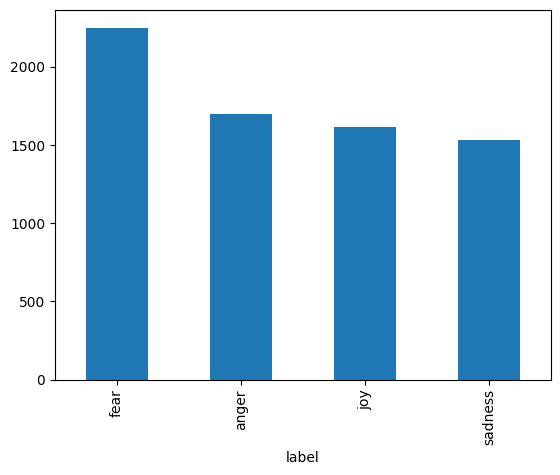

In [ ]:
data["label"].value_counts().plot(kind="bar")

In [ ]:
g=data.groupby("label")

In [ ]:
g.head()

,text,label,text_clean
0,Just got back from seeing @GaryDelaney in Burs...,joy,got back see garydelaney burslem amaz face sti...
1,Oh dear an evening of absolute hilarity I don'...,joy,oh dear even absolut hilar dont think laugh mu...
2,Been waiting all week for this game ❤️❤️❤️ #ch...,joy,wait week game ❤️❤️❤️ cheer friday ❤️
3,"@gardiner_love : Thank you so much, Gloria! Yo...",joy,gardinerlov thank much gloria your sweet thoug...
4,I feel so blessed to work with the family that...,joy,feel bless work famili nanni ❤️ noth love amp ...
823,I feel like I am drowning. #depression #anxiet...,fear,feel like drown depress anxieti falur worthless
824,I get so nervous even thinking about talking t...,fear,get nervou even think talk wanna die
825,I lost my blinders .... #panic,fear,lost blinder panic
826,I feel like I am drowning. #depression #falur...,fear,feel like drown depress falur worthless
827,This is the scariest American Horror Story out...,fear,scariest american horror stori im gonna watch ...


In [ ]:
data=pd.DataFrame(g.apply(lambda x:x.sample(g.size().min()).reset_index(drop=True)))

/tmp/ipykernel_4396/2877666250.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  data=pd.DataFrame(g.apply(lambda x:x.sample(g.size().min()).reset_index(drop=True)))


<Axes: xlabel='label'>

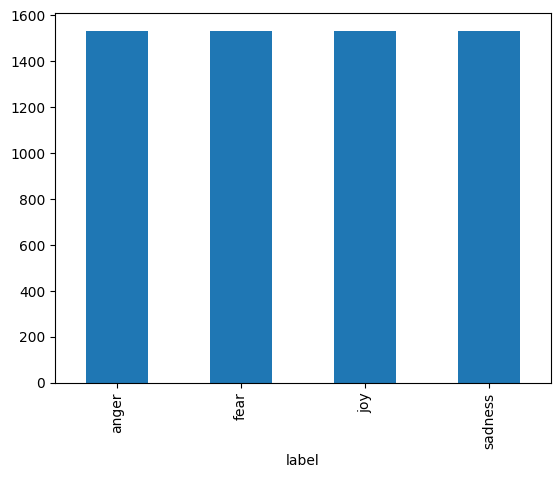

In [ ]:
data["label"].value_counts().plot(kind="bar")

In [ ]:
data["label_int"]=LabelEncoder().fit_transform(data["label"])

In [ ]:
NUM_LABELS=4

In [ ]:
train_split,test_split=train_test_split(data,train_size=0.8)
train_split,val_split=train_test_split(train_split,train_size=0.9)


In [ ]:
print(len(train_split))
print(len(test_split))
print(len(val_split))

4414
1227
491


In [ ]:
train_df=pd.DataFrame({
    "label":train_split.label_int.values,
    "text":train_split.text_clean.values
})
test_df=pd.DataFrame({
    "label":test_split.label_int.values,
    "text":test_split.text_clean.values
})

In [ ]:
test_df=datasets.Dataset.from_dict(test_df)
train_df=datasets.Dataset.from_dict(train_df)

In [ ]:
dataset_dict=datasets.DatasetDict({"train":train_df,"test":test_df})

In [ ]:
dataset_dict

DatasetDict({
    train: Dataset({
        features: ['label', 'text'],
        num_rows: 4414
    })
    test: Dataset({
        features: ['label', 'text'],
        num_rows: 1227
    })
})

CREATE EMBEDDINGS

In [ ]:
tokenizer=XLNetTokenizer.from_pretrained("xlnet-base-cased")

spiece.model:   0%|          | 0.00/798k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.38M [00:00<?, ?B/s]

In [ ]:
def tokenize(examples):
  return tokenizer(examples["text"],padding="max_length",max_length=128,truncation=True)

In [ ]:
tokenized_datasets=dataset_dict.map(tokenize,batched=True)

Map:   0%|          | 0/4414 [00:00<?, ? examples/s]

Map:   0%|          | 0/1227 [00:00<?, ? examples/s]

In [ ]:
tokenized_datasets


DatasetDict({
    train: Dataset({
        features: ['label', 'text', 'input_ids', 'attention_mask'],
        num_rows: 4414
    })
    test: Dataset({
        features: ['label', 'text', 'input_ids', 'attention_mask'],
        num_rows: 1227
    })
})

In [ ]:
print(tokenized_datasets["train"]["input_ids"][0])

[5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 106, 253, 4419, 451, 23, 6447, 23, 25, 1680, 10618, 11233, 1258, 521, 92, 14146, 27896, 10003, 2548, 17, 1653, 19622, 4909, 4, 3]


In [ ]:
tokenizer.decode(5)

'<pad>'

In [ ]:
print(tokenized_datasets["train"]["attention_mask"][0])

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [ ]:
small_train_dataset=tokenized_datasets["train"].shuffle(seed=42).select(range(100))

In [ ]:
small_eval_dataset=tokenized_datasets["test"].shuffle(seed=42).select(range(100))

In [ ]:
small_train_dataset

Dataset({
    features: ['label', 'text', 'input_ids', 'attention_mask'],
    num_rows: 100
})

FINE TUNE OUR MODEL

In [ ]:
model=XLNetForSequenceClassification.from_pretrained("xlnet-base-cased",num_labels=NUM_LABELS,id2label={0:"anger",1:"fear",2:"joy",3:"sadness"})

config.json:   0%|          | 0.00/760 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  467MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  467MB            

Loading weights:   0%|          | 0/206 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

[transformers] XLNetForSequenceClassification LOAD REPORT from: xlnet-base-cased
Key                             | Status     | 
--------------------------------+------------+-
lm_loss.weight                  | UNEXPECTED | 
lm_loss.bias                    | UNEXPECTED | 
sequence_summary.summary.bias   | MISSING    | 
sequence_summary.summary.weight | MISSING    | 
logits_proj.weight              | MISSING    | 
logits_proj.bias                | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
metric=evaluate.load("accuracy")

In [ ]:
def compute_metric(eval_pred):
  logits,labels=eval_pred
  predictions=np.argmax(logits,axis=-1)
  return metric.compute(predictions=predictions,reference=labels)

In [ ]:
training_args=TrainingArguments(output_dir="test_trainer",eval_strategy="epoch",num_train_epochs=3)

In [ ]:
trainer=Trainer(model=model,args=training_args,train_dataset=small_train_dataset,eval_dataset=small_train_dataset,compute_metrics=compute_metric)

In [ ]:
training_args = TrainingArguments(
    output_dir="test_trainer",
    eval_strategy="epoch",
    num_train_epochs=3,
    label_names=["label"] # Specify the label column name
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=small_train_dataset,
    eval_dataset=small_eval_dataset, # Corrected eval_dataset
    compute_metrics=compute_metric
)

trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,No log,No log
2,No log,No log
3,No log,No log


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


TrainOutput(global_step=39, training_loss=1.3586942232572115, metrics={'train_runtime': 785.3447, 'train_samples_per_second': 0.382, 'train_steps_per_second': 0.05, 'total_flos': 21366375321600.0, 'train_loss': 1.3586942232572115, 'epoch': 3.0})

EVALUATE MODEL

In [ ]:
trainer.evaluate()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch
No log,No log,3


{}

In [ ]:
model.save_pretrained("fine-tuned-model")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
fine_tuned_model=XLNetForSequenceClassification.from_pretrained("fine-tuned-model")

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

In [ ]:
clf=pipeline("text-classification",fine_tuned_model,tokenizer=tokenizer)

In [ ]:
randint=random.randint(0,len(val_split))
print(val_split["text_clean"][randint])


say compar other im human lit fire burn


/tmp/ipykernel_4396/1936159703.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(val_split["text_clean"][randint])


In [ ]:
answer=clf(val_split["text_clean"][randint],top_k=None)
print(answer)

/tmp/ipykernel_4396/2899141228.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  answer=clf(val_split["text_clean"][randint],top_k=None)


[{'label': 'joy', 'score': 0.3212638795375824}, {'label': 'fear', 'score': 0.30257952213287354}, {'label': 'anger', 'score': 0.24309684336185455}, {'label': 'sadness', 'score': 0.13305972516536713}]
